# Vietnamese-accented English: current pipeline test

This is a fixed exploratory test of Vietnamese speakers reading English through the current local demo. Raw ASR, recorded normalization (when executed), conversational interpretation, grammar suggestions and bot replies are shown separately. A Qwen interpretation is inferred text, not a verified transcript or a pronunciation reference. The published reading prompt is an intended reference, not an expert transcription of every realized word. WER/CER count differences from that prompt; they do not prove pronunciation or conversational understanding. The four Speech Accent Archive clips share one paragraph. The six L2-ARCTIC clips share one held-out speaker. Ten clips therefore are not ten independent speakers or a broad conversational benchmark.

These cells read recorded results and local audio only. They do not call models, APIs or training.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import Audio, HTML, Markdown, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/report_vi_voice_pipeline.py').is_file())
sys.path.insert(0, str(ROOT))
from scripts.report_vi_voice_pipeline import (attach_text_reviews, audit_sources, metric_table, latency_table, per_case_table, plot_results, case_html, checked_audio, recovery_table, baseline_comparison)
MANIFEST = ROOT/'data/generated/vi-voice-pipeline-v1/manifest.json'
RESULTS = ROOT/'data/generated/vi-voice-pipeline-v1/recovery-v1/results.json'
OUT = ROOT/'data/generated/vi-voice-pipeline-v1/recovery-v1'
manifest = json.loads(MANIFEST.read_text(encoding='utf-8'))
results = attach_text_reviews(json.loads(RESULTS.read_text(encoding='utf-8')), RESULTS)
print('Run:', results['status'], '|', results.get('started_at_utc'))
sources = audit_sources(manifest, results, MANIFEST)
display(sources)

Run: completed | 2026-10-23T03:11:56.528014+00:00


,id,corpus,speaker,seconds,reference_words,audio_sha_verified,status,source,license
0,saa-vietnamese12,Speech Accent Archive,vietnamese12,24.983175,69,True,ready,https://accent.gmu.edu/samples/vietnamese12/,CC-BY-NC-SA-4.0
1,saa-vietnamese13,Speech Accent Archive,vietnamese13,23.776667,69,True,ready,https://accent.gmu.edu/samples/vietnamese13/,CC-BY-NC-SA-4.0
2,saa-vietnamese22,Speech Accent Archive,vietnamese22,26.251043,69,True,ready,https://accent.gmu.edu/samples/vietnamese22/,CC-BY-NC-SA-4.0
3,saa-vietnamese32,Speech Accent Archive,vietnamese32,28.919687,69,True,ready,https://accent.gmu.edu/samples/vietnamese32/,CC-BY-NC-SA-4.0
4,l2-TLV-arctic_a0082,L2-ARCTIC,TLV,2.000000,6,True,ready,https://psi.engr.tamu.edu/l2-arctic-corpus/,CC-BY-NC-4.0
5,l2-TLV-arctic_b0261,L2-ARCTIC,TLV,2.001723,6,True,ready,https://psi.engr.tamu.edu/l2-arctic-corpus/,CC-BY-NC-4.0
6,l2-TLV-arctic_a0225,L2-ARCTIC,TLV,4.640000,13,True,ready,https://psi.engr.tamu.edu/l2-arctic-corpus/,CC-BY-NC-4.0
7,l2-TLV-arctic_a0426,L2-ARCTIC,TLV,4.690249,10,True,ready,https://psi.engr.tamu.edu/l2-arctic-corpus/,CC-BY-NC-4.0
8,l2-TLV-arctic_a0510,L2-ARCTIC,TLV,6.104558,11,True,ready,https://psi.engr.tamu.edu/l2-arctic-corpus/,CC-BY-NC-4.0
9,l2-TLV-arctic_a0147,L2-ARCTIC,TLV,6.443447,13,True,ready,https://psi.engr.tamu.edu/l2-arctic-corpus/,CC-BY-NC-4.0


## Source and protocol audit

Selection is frozen before inference. Original full clips are used; downloads longer than the demo 30-second input limit were excluded rather than cropped. The same paragraph is repeated across Speech Accent Archive speakers. TLV is held out from ASR-v1 training but is part of an existing test corpus, not a newly independent dataset.

In [2]:
print(manifest['selection'])
print(manifest['protocol'])
display(sources.groupby('corpus').agg(clips=('id','size'), speakers=('speaker','nunique'), audio_seconds=('seconds','sum'), intended_words=('reference_words','sum')).round(3))
display(pd.DataFrame(manifest.get('excluded_downloads', [])))
display({key: results.get(key) for key in ['voice_api_calls','audio_sent_externally','training_started','references_submitted_to_models','runtime_source_changed','manifest_changed']})
display(results['identity']['config'])

Fixed before inference: four full SAA clips within 30s; six ASR test TLV clips, two per duration bucket (0,3],(3,5],(5,30], SHA256 order seed vi-voice-pipeline-v1.
Every clip is submitted once, whole, with empty history and no reference_text. Source/reference is used for scoring only. No training or TTS.


,clips,speakers,audio_seconds,intended_words
corpus,,,,
L2-ARCTIC,6,1,25.880,59
Speech Accent Archive,4,4,103.931,276


,id,audio,source_url,duration_sec,sample_rate,channels,sha256,reason
0,vietnamese1,data/external/speech-accent-archive-vietnamese...,https://accent.gmu.edu/audio/vietnamese1.mp3,41.714240,44100,1,863c02fa3865691acedf1c7085764faf90bd6850357d2f...,Exceeds the current demo 30-second input limit...
1,vietnamese2,data/external/speech-accent-archive-vietnamese...,https://accent.gmu.edu/audio/vietnamese2.mp3,35.104467,44100,1,248af35154123f67256bfa6cfd3cf2d68ac260ccb81c4a...,Exceeds the current demo 30-second input limit...
2,vietnamese3,data/external/speech-accent-archive-vietnamese...,https://accent.gmu.edu/audio/vietnamese3.mp3,32.981429,44100,1,8c802323b25ade05a607dea2c8cf85b7f60994f319d3e7...,Exceeds the current demo 30-second input limit...


{'voice_api_calls': 0,
 'audio_sent_externally': False,
 'training_started': False,
 'references_submitted_to_models': False,
 'runtime_source_changed': False,
 'manifest_changed': False}

{'asr_model_id': 'wav2vec2-vi-en-v1',
 'grammar_model_id': 'qwen-grammar',
 'reply_model_id': 'qwen-base',
 'device': 'auto',
 'threads': 2,
 'acoustic_device': 'cpu',
 'transcript_normalization': 'lexical_preserving_v1',
 'transcript_recovery': 'guarded_intent_recovery_v1'}

## WER, CER and exact prompt matches

Micro averages sum edits and reference lengths over ready requests. Failures remain in the report and are excluded from scoring denominators. Case and punctuation are ignored. Text stages are not a before/after training comparison. Recovered text is inferred; a lower prompt edit count does not verify its spoken meaning. When normalization metadata is empty, the Normalized compatibility column contains raw ASR fallback; it does not represent another executed normalization/LLM operation. Grammar suggestions and bot replies are not treated as ASR transcripts.

In [3]:
metrics = metric_table(results['records'])
display(metrics.round(3))
metrics.to_csv(OUT/'metrics.csv', index=False)
cases = per_case_table(results['records'])
display(cases)
cases.to_csv(OUT/'per-case.csv', index=False)
recoveries = recovery_table(results['records'])
display(recoveries)
recoveries.to_csv(OUT/'recovery-status.csv', index=False)

,corpus,text_stage,selected_clips,ready_clips,failed_clips,reference_words,word_errors,WER (%),reference_chars,char_errors,CER (%),exact_prompt_matches
0,All clips,Raw ASR,10,10,0,335,109,32.537,1662,236,14.200,0
1,All clips,Normalized,10,10,0,335,109,32.537,1662,236,14.200,0
2,All clips,Conversation interpretation,10,10,0,335,109,32.537,1662,236,14.200,0
3,L2-ARCTIC,Raw ASR,6,6,0,59,22,37.288,298,56,18.792,0
4,L2-ARCTIC,Normalized,6,6,0,59,22,37.288,298,56,18.792,0
5,L2-ARCTIC,Conversation interpretation,6,6,0,59,22,37.288,298,56,18.792,0
6,Speech Accent Archive,Raw ASR,4,4,0,276,87,31.522,1364,180,13.196,0
7,Speech Accent Archive,Normalized,4,4,0,276,87,31.522,1364,180,13.196,0
8,Speech Accent Archive,Conversation interpretation,4,4,0,276,87,31.522,1364,180,13.196,0


,id,status,reference,raw_asr,normalized,conversation_text,interpretation_status,interpretation_reason,interpretation_requires_confirmation,conversation_source,raw_word_errors,conversation_word_errors,reference_words,reply,error
0,saa-vietnamese12,ready,Please call Stella. Ask her to bring these thi...,Please cos stella asked her to bring these thi...,Please cos stella asked her to bring these thi...,Please cos stella asked her to bring these thi...,ambiguous,unclear_intent,True,asr,7,7,69,"Could you clarify what ""green flerm"" refers to?",None
1,saa-vietnamese13,ready,Please call Stella. Ask her to bring these thi...,Please call stellar ask er to bring these thin...,Please call stellar ask er to bring these thin...,Please call stellar ask er to bring these thin...,ambiguous,unclear_intent,True,asr,33,33,69,"Could you clarify what ""six poons of frea snow...",None
2,saa-vietnamese22,ready,Please call Stella. Ask her to bring these thi...,Please go steller ask her to bring these thing...,Please go steller ask her to bring these thing...,Please go steller ask her to bring these thing...,ambiguous,unclear_intent,True,asr,24,24,69,"Could you clarify what ""green flerm"" refers to?",None
3,saa-vietnamese32,ready,Please call Stella. Ask her to bring these thi...,Please constella ask her to bring these things...,Please constella ask her to bring these things...,Please constella ask her to bring these things...,ambiguous,unclear_intent,True,asr,23,23,69,"Could you clarify what ""fashional pea"" refers to?",None
4,l2-TLV-arctic_a0082,ready,His face was streaming with blood,His face were dreaming with blood,His face were dreaming with blood,His face were dreaming with blood,unavailable,function_word_change,False,asr,2,2,6,That must be a relief after all that effort.,None
5,l2-TLV-arctic_b0261,ready,And he did hurt my arm,And he dishurt my m,And he dishurt my m,And he dishurt my m,ambiguous,unclear_intent,True,asr,3,3,6,"Could you clarify what ""dishurt my m"" refers to?",None
6,l2-TLV-arctic_a0225,ready,I was brought up the way most girls in Hawaii ...,I well brought off the way most gur in her win...,I well brought off the way most gur in her win...,I well brought off the way most gur in her win...,ambiguous,unclear_intent,True,asr,7,7,13,"Could you clarify what ""narg"" refers to?",None
7,l2-TLV-arctic_a0426,ready,They do not know the length of time of incubation,They do not know the length of time of incobation,They do not know the length of time of incobation,They do not know the length of time of incobation,ambiguous,unclear_intent,True,asr,1,1,10,"Could you clarify what ""incobation"" refers to ...",None
8,l2-TLV-arctic_a0510,ready,Much more Ernest told them of themselves and o...,Must more onles tonthem up themselves op his d...,Must more onles tonthem up themselves op his d...,Must more onles tonthem up themselves op his d...,ambiguous,unclear_intent,True,asr,8,8,11,"Could you clarify what ""op his dissolutionman""...",None
9,l2-TLV-arctic_a0147,ready,A moment before he was intoxicated by a joy th...,A moment before he was intoxicated by joy that...,A moment before he was intoxicated by joy that...,A moment before he was intoxicated by joy that...,unchanged,None,False,asr_interpreted,1,1,13,"That moment was almost a blur of joy, but it l...",None


,request_status,interpretation_status,reason,requires_confirmation,clips
0,ready,ambiguous,unclear_intent,True,8
1,ready,unavailable,function_word_change,False,1
2,ready,unchanged,none,False,1


## Response time and visualizations

Observed times include local HTTP polling and queue wait. No ai33 call is included. The first request is not assumed to be cold.

,id,corpus,status,Reply ready (s),All feedback ready (s),Submission wait (s),Normalization (s),Interpretation (s)
0,saa-vietnamese12,Speech Accent Archive,ready,21.234,72.391,0.016,None,6.719
1,saa-vietnamese13,Speech Accent Archive,ready,30.437,49.844,0.062,None,10.468
2,saa-vietnamese22,Speech Accent Archive,ready,22.578,32.938,0.031,None,5.657
3,saa-vietnamese32,Speech Accent Archive,ready,12.532,23.328,0.047,None,1.016
4,l2-TLV-arctic_a0082,L2-ARCTIC,ready,3.516,4.859,0.031,None,1.204
5,l2-TLV-arctic_b0261,L2-ARCTIC,ready,3.109,4.750,0.031,None,0.906
6,l2-TLV-arctic_a0225,L2-ARCTIC,ready,4.407,7.282,0.032,None,1.047
7,l2-TLV-arctic_a0426,L2-ARCTIC,ready,4.500,7.406,0.031,None,0.984
8,l2-TLV-arctic_a0510,L2-ARCTIC,ready,6.344,8.782,0.016,None,1.187
9,l2-TLV-arctic_a0147,L2-ARCTIC,ready,7.187,9.828,0.000,None,1.735


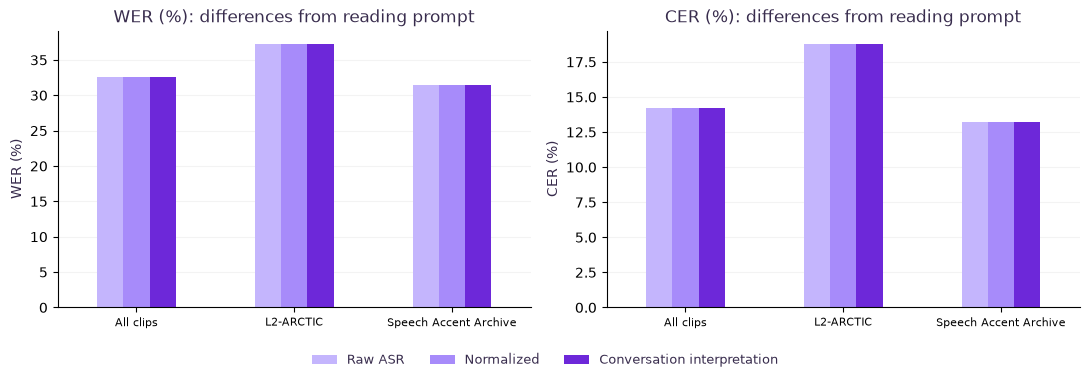

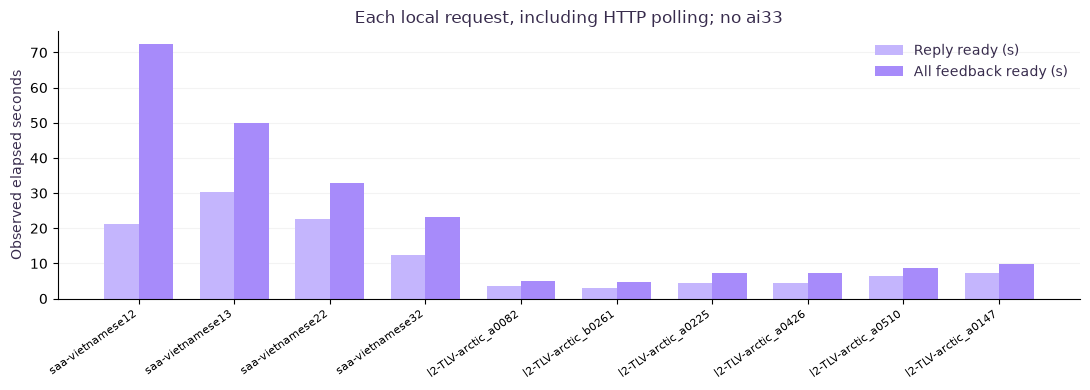

In [4]:
latencies = latency_table(results['records'])
display(latencies.round(3))
latencies.to_csv(OUT/'latencies.csv', index=False)
plot_results(metrics, latencies, OUT)

## Original audio, transcripts and actual bot replies

Each player embeds the complete original recording in this notebook. Published reference, raw ASR, normalized input, Qwen recovery, grammar feedback and actual bot reply remain separate. Assistant text reviews, when present, are subjective text-only observations. They are not expert listening, semantic accuracy scores or pronunciation labels. Expert audio/semantic review remains pending.

In [5]:
by_id = {case['id']: case for case in manifest['cases']}
for row in results['records']:
    display(Markdown('### ' + row['id']))
    display(Audio(filename=str(checked_audio(row['audio'])), embed=True))
    display(HTML(case_html(row, by_id[row['id']], OUT, include_audio=False)))

### saa-vietnamese12

### saa-vietnamese13

### saa-vietnamese22

### saa-vietnamese32

### l2-TLV-arctic_a0082

### l2-TLV-arctic_b0261

### l2-TLV-arctic_a0225

### l2-TLV-arctic_a0426

### l2-TLV-arctic_a0510

### l2-TLV-arctic_a0147

## Runtime provenance and limitations

The conversation model receives recognized text or a guarded Qwen interpretation, without listening to the audio itself. ASR and interpretation errors can therefore change the subject of a fluent reply. No automatic semantic accuracy score is derived from WER. These read-speech clips with empty history do not establish natural multi-turn conversation quality.

In [6]:
display(results['identity'])
display(results.get('assistant_review_metadata', {}))
display(pd.DataFrame([{'id': r['id'], 'models': r.get('models'), 'qwen_runtime': r.get('qwen_runtime'), 'reply_diagnostics': r.get('reply_diagnostics'), 'error': r.get('error')} for r in results['records']]))
for limitation in results.get('limitations', []):
    print('-', limitation)

{'manifest_sha256': '6dc37aff9c83a7f499568e065b927efdc7b7c17a4665edf6d45673d58d556db5',
 'case_ids': ['saa-vietnamese12',
  'saa-vietnamese13',
  'saa-vietnamese22',
  'saa-vietnamese32',
  'l2-TLV-arctic_a0082',
  'l2-TLV-arctic_b0261',
  'l2-TLV-arctic_a0225',
  'l2-TLV-arctic_a0426',
  'l2-TLV-arctic_a0510',
  'l2-TLV-arctic_a0147'],
 'config': {'asr_model_id': 'wav2vec2-vi-en-v1',
  'grammar_model_id': 'qwen-grammar',
  'reply_model_id': 'qwen-base',
  'device': 'auto',
  'threads': 2,
  'acoustic_device': 'cpu',
  'transcript_normalization': 'lexical_preserving_v1',
  'transcript_recovery': 'guarded_intent_recovery_v1'},
 'source_sha256': {'scripts/benchmark_demo_latency.py': '8f29e9d1f315b311ca02d4f5417fcb78eb42aae3c4e856ada41a89ef5aed202c',
  'scripts/local_chat_worker.py': '6eba885479c3b603e62ae5697acc351b0098d0185b6d029a2b42e4d6db1e87f3',
  'scripts/local_chat_process.py': 'a055e780311cd467bf70d11ec1ac42c664a647678086b813b4ca162267d98bd1',
  'scripts/local_speech_engine.py': '

{'reviewer': 'Codex assistant',
 'review_kind': 'subjective_text_only_diagnostic',
 'created_at_utc': '2026-10-23T03:16:59.647700+00:00',
 'results_sha256': '80f5e3c2cac6b9c44515c94ca28649bdb3e41d911d682976362f4d08d15f0afd',
 'expert_listening_completed': False,
 'official_semantic_accuracy': None,
 'scope': 'Text-only comparison of published reading prompts, raw ASR, accepted conversation text and replies. No expert listening or human-verified realized-word transcription. Reading-prompt WER is not semantic accuracy.'}

,id,models,qwen_runtime,reply_diagnostics,error
0,saa-vietnamese12,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
1,saa-vietnamese13,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
2,saa-vietnamese22,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
3,saa-vietnamese32,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
4,l2-TLV-arctic_a0082,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
5,l2-TLV-arctic_b0261,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
6,l2-TLV-arctic_a0225,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
7,l2-TLV-arctic_a0426,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
8,l2-TLV-arctic_a0510,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None
9,l2-TLV-arctic_a0147,"{'asr_model': 'wav2vec2-vi-en-v1', 'phoneme_mo...","{'requested': 'auto', 'device': 'cuda:0', 'dty...","{'omitted_leading_echoes': [], 'omitted_echoes...",None


- Published reading prompts are not verified transcripts of every realized word.
- Selection is fixed before inference; this is exploratory evaluation, not threshold fitting.
- WER/CER ignore capitalization and punctuation; no semantic accuracy score is inferred.
- Qwen conversation receives only the recognized text and its configured formatting or intent recovery, never the reference.
- An inferred recovery is not proof of the realized spoken words; raw pronunciation references remain unchanged unless confirmed.
- No AI33 or other speech synthesis is measured. Timing includes local polling overhead.


## Same-audio previous-run comparison

Both runs must contain the same unique IDs, audio bytes and intended prompts. This compares recorded pipeline versions, not a new ASR training checkpoint or a controlled causal experiment. Failed pairs remain visible. Prompt edit counts do not establish semantic correctness.

In [7]:
BASELINE = ROOT/'data/generated/vi-voice-pipeline-v1/current/results.json'
baseline = json.loads(BASELINE.read_text(encoding='utf-8'))
paired = baseline_comparison(results, baseline)
display(paired)
paired.to_csv(OUT/'baseline-comparison.csv', index=False)
display({'baseline_config': baseline['identity']['config'], 'current_config': results['identity']['config']})
eligible = paired[paired['paired_ready']]
print('Paired ready:', len(eligible), '/', len(paired))
print('Raw ASR token sequences unchanged:', int(paired['raw_asr_tokens_equal'].sum()), '/', len(paired))
denominator = int(eligible['reference_words'].sum())
if denominator:
    for field in ['baseline_word_errors', 'current_word_errors']:
        print(field, ':', int(eligible[field].sum()), '/', denominator, '=', round(100*eligible[field].sum()/denominator, 3), '%')

,id,baseline_status,current_status,paired_ready,baseline_raw_asr,current_raw_asr,raw_asr_tokens_equal,baseline_conversation_text,current_conversation_text,baseline_word_errors,current_word_errors,reference_words,baseline_reply,current_reply
0,saa-vietnamese12,ready,ready,True,Please cos stella asked her to bring these thi...,Please cos stella asked her to bring these thi...,True,Please cos stella asked her to bring these thi...,Please cos stella asked her to bring these thi...,7,7,69,I'm glad you're happy! Let me know if you need...,"Could you clarify what ""green flerm"" refers to?"
1,saa-vietnamese13,ready,ready,True,Please call stellar ask er to bring these thin...,Please call stellar ask er to bring these thin...,True,Please call stellar ask er to bring these thin...,Please call stellar ask er to bring these thin...,33,33,69,I'll need to check the store for the items you...,"Could you clarify what ""six poons of frea snow..."
2,saa-vietnamese22,ready,ready,True,Please go steller ask her to bring these thing...,Please go steller ask her to bring these thing...,True,Please go steller ask her to bring these thing...,Please go steller ask her to bring these thing...,24,24,69,I see. That sounds like a great plan. Let me k...,"Could you clarify what ""green flerm"" refers to?"
3,saa-vietnamese32,ready,ready,True,Please constella ask her to bring these things...,Please constella ask her to bring these things...,True,Please constella ask her to bring these things...,Please constella ask her to bring these things...,23,23,69,That's a great plan! I'll make sure to check a...,"Could you clarify what ""fashional pea"" refers to?"
4,l2-TLV-arctic_a0082,ready,ready,True,His face were dreaming with blood,His face were dreaming with blood,True,His face were dreaming with blood.,His face were dreaming with blood,2,2,6,His face was dreaming with blood.,That must be a relief after all that effort.
5,l2-TLV-arctic_b0261,ready,ready,True,And he dishurt my m,And he dishurt my m,True,And he dishurt my m.,And he dishurt my m,3,3,6,That must be a relief after all that effort.,"Could you clarify what ""dishurt my m"" refers to?"
6,l2-TLV-arctic_a0225,ready,ready,True,I well brought off the way most gur in her win...,I well brought off the way most gur in her win...,True,I well brought off the way most gur in her win...,I well brought off the way most gur in her win...,7,7,13,That must be a relief after all that effort.,"Could you clarify what ""narg"" refers to?"
7,l2-TLV-arctic_a0426,ready,ready,True,They do not know the length of time of incobation,They do not know the length of time of incobation,True,They do not know the length of time of incobat...,They do not know the length of time of incobation,1,1,10,They don't know the length of time it takes fo...,"Could you clarify what ""incobation"" refers to ..."
8,l2-TLV-arctic_a0510,ready,ready,True,Must more onles tonthem up themselves op his d...,Must more onles tonthem up themselves op his d...,True,Must more onles tonthem up themselves op his d...,Must more onles tonthem up themselves op his d...,8,8,11,"Could you clarify what ""op his dissolution man...","Could you clarify what ""op his dissolutionman""..."
9,l2-TLV-arctic_a0147,ready,ready,True,A moment before he was intoxicated by joy that...,A moment before he was intoxicated by joy that...,True,A moment before he was intoxicated by joy that...,A moment before he was intoxicated by joy that...,1,1,13,That's a powerful description! I'm glad you fo...,"That moment was almost a blur of joy, but it l..."


{'baseline_config': {'asr_model_id': 'wav2vec2-vi-en-v1',
  'grammar_model_id': 'qwen-grammar',
  'reply_model_id': 'qwen-base',
  'device': 'auto',
  'threads': 2,
  'acoustic_device': 'cpu',
  'transcript_normalization': 'lexical_preserving_v1'},
 'current_config': {'asr_model_id': 'wav2vec2-vi-en-v1',
  'grammar_model_id': 'qwen-grammar',
  'reply_model_id': 'qwen-base',
  'device': 'auto',
  'threads': 2,
  'acoustic_device': 'cpu',
  'transcript_normalization': 'lexical_preserving_v1',
  'transcript_recovery': 'guarded_intent_recovery_v1'}}

Paired ready: 10 / 10
Raw ASR token sequences unchanged: 10 / 10
baseline_word_errors : 109 / 335 = 32.537 %
current_word_errors : 109 / 335 = 32.537 %
